#  **Flight Fare Prediction**



## **Introduction**

Flight ticket prices are highly dynamic and depend on multiple factors such as airline, duration, number of stops, and time of journey. Predicting these prices can help users make better booking decisions.

### **Objective**

Analyze flight data to identify key factors affecting prices
Build machine learning models to predict ticket prices
Evaluate model performance and compare different approaches.
### **Dataset Overview**
The dataset contains 10,000+ records with the following features:

Airline,
Source & Destination,
Duration,
Total Stops,
Date & Time,
Price (Target Variable).  

## **Import Libraries**

In this section, we import all the necessary libraries required for data analysis, visualization, preprocessing, and model building.

In [47]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, RandomizedSearchCV, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from xgboost import XGBRegressor

import warnings
warnings.filterwarnings('ignore')
print("Libraries imported")


Libraries imported


## **Load Dataset**

In this step, we load the dataset into the environment and inspect its structure to understand the available features and data types.

In [48]:
from google.colab import files
x = files.upload()


Saving Flight_Fare.xlsx to Flight_Fare (1).xlsx


In [49]:
df = pd.read_excel("Flight_Fare.xlsx")


## **Basic Data Checks**

Before building any model, it is important to understand the structure of the dataset. This includes checking the number of rows and columns, data types, statistical summary, and missing values.

### Data types and column info

In [50]:
df.head()

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price
0,IndiGo,24/03/2019,Banglore,New Delhi,BLR → DEL,22:20,01:10 22 Mar,2h 50m,non-stop,No info,3897
1,Air India,1/05/2019,Kolkata,Banglore,CCU → IXR → BBI → BLR,05:50,13:15,7h 25m,2 stops,No info,7662
2,Jet Airways,9/06/2019,Delhi,Cochin,DEL → LKO → BOM → COK,09:25,04:25 10 Jun,19h,2 stops,No info,13882
3,IndiGo,12/05/2019,Kolkata,Banglore,CCU → NAG → BLR,18:05,23:30,5h 25m,1 stop,No info,6218
4,IndiGo,01/03/2019,Banglore,New Delhi,BLR → NAG → DEL,16:50,21:35,4h 45m,1 stop,No info,13302


In [51]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10683 entries, 0 to 10682
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Airline          10683 non-null  object
 1   Date_of_Journey  10683 non-null  object
 2   Source           10683 non-null  object
 3   Destination      10683 non-null  object
 4   Route            10682 non-null  object
 5   Dep_Time         10683 non-null  object
 6   Arrival_Time     10683 non-null  object
 7   Duration         10683 non-null  object
 8   Total_Stops      10682 non-null  object
 9   Additional_Info  10683 non-null  object
 10  Price            10683 non-null  int64 
dtypes: int64(1), object(10)
memory usage: 918.2+ KB


In [52]:
print("Shape:", df.shape)

Shape: (10683, 11)


In [53]:
df.tail()

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price
10678,Air Asia,9/04/2019,Kolkata,Banglore,CCU → BLR,19:55,22:25,2h 30m,non-stop,No info,4107
10679,Air India,27/04/2019,Kolkata,Banglore,CCU → BLR,20:45,23:20,2h 35m,non-stop,No info,4145
10680,Jet Airways,27/04/2019,Banglore,Delhi,BLR → DEL,08:20,11:20,3h,non-stop,No info,7229
10681,Vistara,01/03/2019,Banglore,New Delhi,BLR → DEL,11:30,14:10,2h 40m,non-stop,No info,12648
10682,Air India,9/05/2019,Delhi,Cochin,DEL → GOI → BOM → COK,10:55,19:15,8h 20m,2 stops,No info,11753


In [54]:
df.describe()

,Price
count,10683.000000
mean,9087.064121
std,4611.359167
min,1759.000000
25%,5277.000000
50%,8372.000000
75%,12373.000000
max,79512.000000


### Statistical summary

In [55]:
df.describe()

,Price
count,10683.000000
mean,9087.064121
std,4611.359167
min,1759.000000
25%,5277.000000
50%,8372.000000
75%,12373.000000
max,79512.000000


### **Missing values**

Check for any missing (null) values in the dataset using df.isnull().sum().

The Route and Total_Stops columns each have 1 missing value. Since the count is very small, we simply drop those rows using dropna().

In [56]:
df.isnull().sum()

,0
Airline,0
Date_of_Journey,0
Source,0
Destination,0
Route,1
Dep_Time,0
Arrival_Time,0
Duration,0
Total_Stops,1
Additional_Info,0


- The dataset contains both categorical and numerical features
- The target variable is **Price**
- Some columns such as date and time require preprocessing

This step helps us understand the structure and quality of the data before cleaning.

## **Data Cleaning**


Data preprocessing is required to:
- Handle missing values
- Convert date and time into useful features
- Prepare data for machine learning models

This step ensures the dataset is clean and structured.



Route and Total_Stops each have 1 missing value — we simply drop those rows.

In [57]:
df.dropna(inplace=True)
print("Shape after cleaning:", df.shape)


Shape after cleaning: (10682, 11)


## **Feature Engineering**

- Extracted journey day and month from date
- Converted time columns into numerical format
- Transformed duration into usable numeric values

These transformations help models understand temporal patterns in pricing.

ML models can't read dates or time strings. We convert them into numbers.

### **Journey Date - Day, Month, Weekday**

We extract day and month from the journey date to capture seasonal trends in flight prices.

In [58]:
df['Date_of_Journey'] = pd.to_datetime(df['Date_of_Journey'])
df['Journey_Day']       = df['Date_of_Journey'].dt.day
df['Journey_Month']     = df['Date_of_Journey'].dt.month
df['Journey_DayOfWeek'] = df['Date_of_Journey'].dt.dayofweek
df.drop('Date_of_Journey', axis=1, inplace=True)


In [59]:
df.head()

,Airline,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price,Journey_Day,Journey_Month,Journey_DayOfWeek
0,IndiGo,Banglore,New Delhi,BLR → DEL,22:20,01:10 22 Mar,2h 50m,non-stop,No info,3897,24,3,6
1,Air India,Kolkata,Banglore,CCU → IXR → BBI → BLR,05:50,13:15,7h 25m,2 stops,No info,7662,1,5,2
2,Jet Airways,Delhi,Cochin,DEL → LKO → BOM → COK,09:25,04:25 10 Jun,19h,2 stops,No info,13882,9,6,6
3,IndiGo,Kolkata,Banglore,CCU → NAG → BLR,18:05,23:30,5h 25m,1 stop,No info,6218,12,5,6
4,IndiGo,Banglore,New Delhi,BLR → NAG → DEL,16:50,21:35,4h 45m,1 stop,No info,13302,1,3,4


### **Departure Time - Hour, Minute**

Departure and arrival times are converted into hours to understand how time impacts ticket pricing.

In [60]:
if 'Dep_Time' in df.columns:
    df['Dep_Time'] = pd.to_datetime(df['Dep_Time'])
    df['Dep_Hour'] = df['Dep_Time'].dt.hour
    df['Dep_Min']  = df['Dep_Time'].dt.minute
    df.drop('Dep_Time', axis=1, inplace=True)


### **Arrival Time - Hour, Minute**

In [61]:
if 'Arrival_Time' in df.columns:
    df['Arrival_Time'] = pd.to_datetime(df['Arrival_Time'])
    df['Arrival_Hour'] = df['Arrival_Time'].dt.hour
    df['Arrival_Min']  = df['Arrival_Time'].dt.minute
    df.drop('Arrival_Time', axis=1, inplace=True)


### **Duration - Hours and Minutes**

Duration is converted into total minutes to make it a numerical feature suitable for machine learning models.

In [62]:
if 'Duration' in df.columns:
    if pd.api.types.is_numeric_dtype(df['Duration']):
        df['Duration_Hours']   = df['Duration'] // 60
        df['Duration_Minutes'] = df['Duration'] % 60
    else:
        df['Duration_Hours']   = df['Duration'].str.extract(r'(\d+)h').fillna(0).astype(int)
        df['Duration_Minutes'] = df['Duration'].str.extract(r'(\d+)m').fillna(0).astype(int)
    df.drop('Duration', axis=1, inplace=True)


### **Total Stops - Numbers (0, 1, 2, 3, 4)**

The number of stops is converted into numerical values since it is an ordinal feature.

In [63]:
df['Total_Stops'] = df['Total_Stops'].map({
    'non-stop': 0, '1 stop': 1, '2 stops': 2, '3 stops': 3, '4 stops': 4
})


### **Drop unused columns**

In [64]:
for col in ['Route', 'Additional_Info']:
    if col in df.columns:
        df.drop(col, axis=1, inplace=True)
print("Final columns:", list(df.columns))


Final columns: ['Airline', 'Source', 'Destination', 'Total_Stops', 'Price', 'Journey_Day', 'Journey_Month', 'Journey_DayOfWeek', 'Dep_Hour', 'Dep_Min', 'Arrival_Hour', 'Arrival_Min', 'Duration_Hours', 'Duration_Minutes']


## **Exploratory Data Analysis (EDA)**

EDA helps us understand relationships between features and the target variable (Price).

We analyze:
- Raw vs Log
- Airline vs Price
- Duration vs Price



### **Price Distribution — Raw vs Log**

This shows why we need log transformation — raw price is skewed.

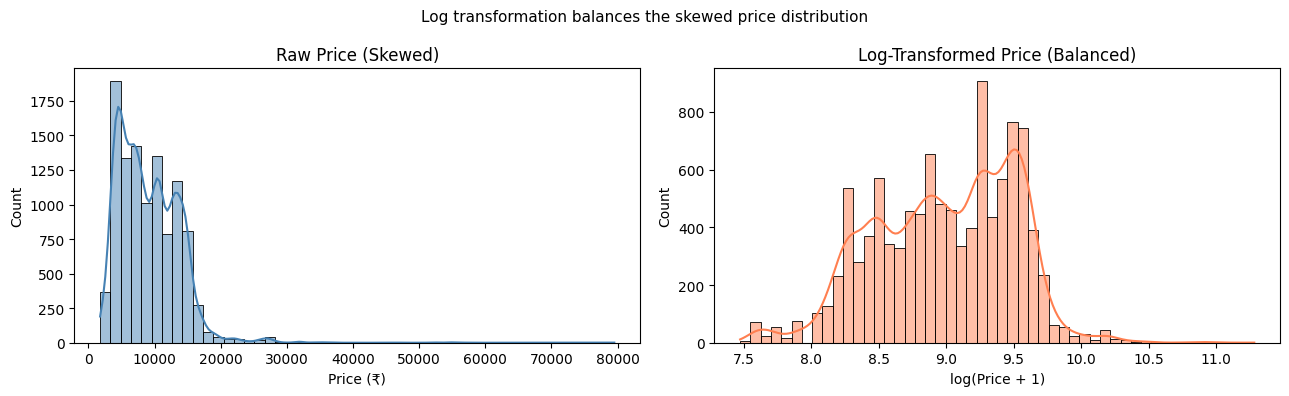

In [65]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.histplot(df['Price'], bins=50, kde=True, ax=axes[0], color='steelblue')
axes[0].set_title("Raw Price (Skewed)")
axes[0].set_xlabel("Price (₹)")

sns.histplot(np.log1p(df['Price']), bins=50, kde=True, ax=axes[1], color='coral')
axes[1].set_title("Log-Transformed Price (Balanced)")
axes[1].set_xlabel("log(Price + 1)")

plt.suptitle("Log transformation balances the skewed price distribution", fontsize=11)
plt.tight_layout()
plt.show()


### **Airline vs Average Price**

This shows which airlines are expensive — useful business insight.

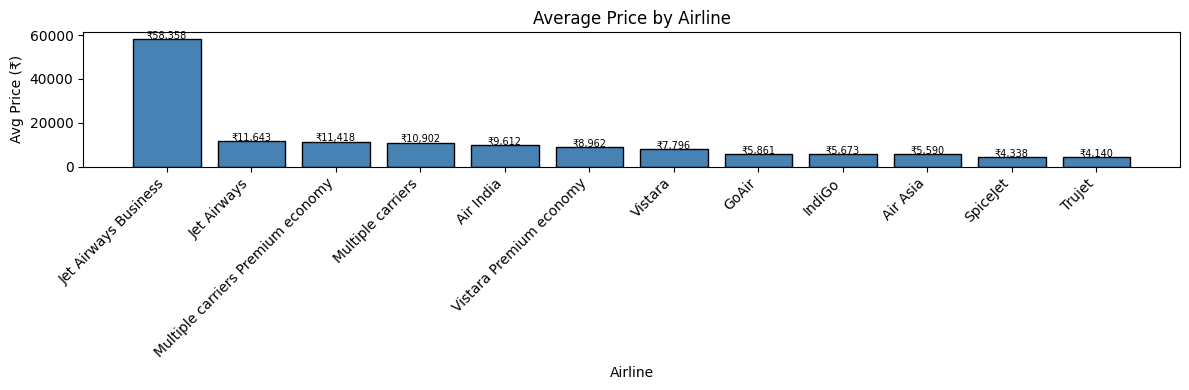

Insight: Jet Airways Business is most expensive. IndiGo is budget-friendly.


In [66]:
airline_avg = df.groupby('Airline')['Price'].mean().sort_values(ascending=False)

plt.figure(figsize=(12, 4))
bars = plt.bar(airline_avg.index, airline_avg.values, color='steelblue', edgecolor='black')
plt.title("Average Price by Airline")
plt.xlabel("Airline")
plt.ylabel("Avg Price (₹)")
plt.xticks(rotation=45, ha='right')
for bar, val in zip(bars, airline_avg.values):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 80,
             f'₹{int(val):,}', ha='center', fontsize=7)
plt.tight_layout()
plt.show()
print("Insight: Jet Airways Business is most expensive. IndiGo is budget-friendly.")


### **Duration vs Price**

Longer flights cost more — this confirms Duration is an important feature.

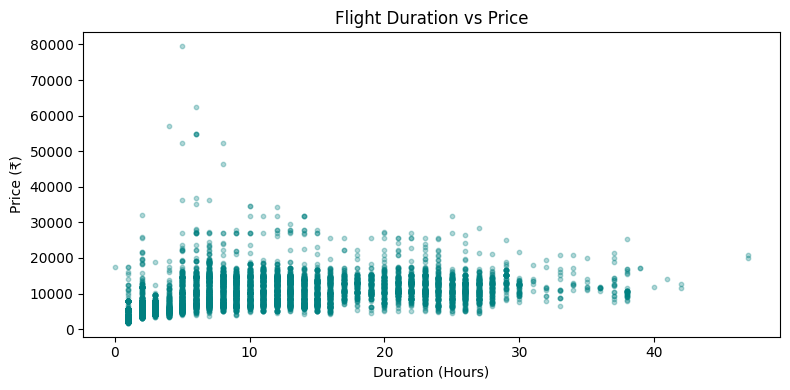

Insight: Longer flights generally cost more. Duration is a strong predictor.


In [67]:
plt.figure(figsize=(8, 4))
plt.scatter(df['Duration_Hours'], df['Price'], alpha=0.3, s=10, color='teal')
plt.title("Flight Duration vs Price")
plt.xlabel("Duration (Hours)")
plt.ylabel("Price (₹)")
plt.tight_layout()
plt.show()
print("Insight: Longer flights generally cost more. Duration is a strong predictor.")


## **Correlation Heatmap**

Shows how strongly each numeric feature is related to Price.

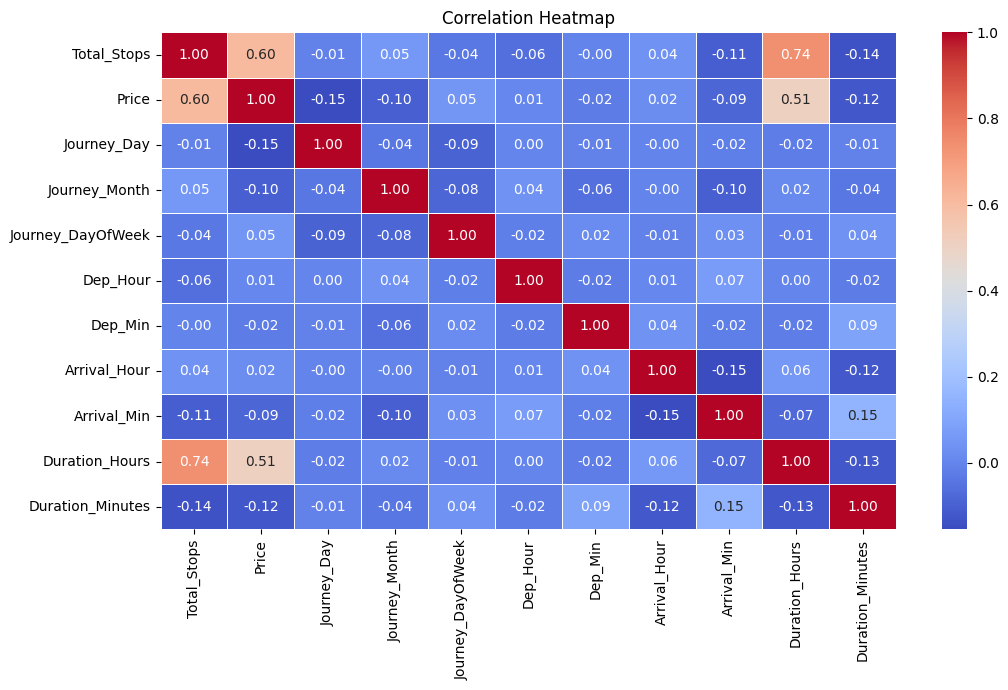

Duration_Hours has the strongest positive correlation with Price.


In [68]:
plt.figure(figsize=(11, 7))
corr = df.corr(numeric_only=True)
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', linewidths=0.5)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()
print("Duration_Hours has the strongest positive correlation with Price.")


## **Remove Outliers**

We remove the bottom 1% and top 1% of prices to avoid extreme values affecting the model.

In [71]:
q1  = df['Price'].quantile(0.01)
q99 = df['Price'].quantile(0.99)
df  = df[(df['Price'] > q1) & (df['Price'] < q99)]
print("Shape after outlier removal:", df.shape)
print(f"Price range: ₹{df['Price'].min():,.0f} – ₹{df['Price'].max():,.0f}")


Shape after outlier removal: (9984, 14)
Price range: ₹3,311 – ₹17,019


## **Define Features (X) and Target (y)**

X = all input columns. y = Price (log-transformed).

In [72]:
X = df.drop('Price', axis=1)
y = np.log1p(df['Price'])
print("Features:", X.shape[1], "| Rows:", X.shape[0])


Features: 13 | Rows: 9984


In [73]:
X.head()

,Airline,Source,Destination,Total_Stops,Journey_Day,Journey_Month,Journey_DayOfWeek,Dep_Hour,Dep_Min,Arrival_Hour,Arrival_Min,Duration_Hours,Duration_Minutes
0,IndiGo,Banglore,New Delhi,0,24,3,6,22,20,1,10,2,50
1,Air India,Kolkata,Banglore,2,1,5,2,5,50,13,15,7,25
2,Jet Airways,Delhi,Cochin,2,9,6,6,9,25,4,25,19,0
3,IndiGo,Kolkata,Banglore,1,12,5,6,18,5,23,30,5,25
4,IndiGo,Banglore,New Delhi,1,1,3,4,16,50,21,35,4,45


## **Train-Test Split**

We split the data into 80% training and 20% testing sets using a fixed random seed (random_state=42) for reproducibility. The test set is held back and only used to evaluate the final model performance.

In [74]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print("Train:", X_train.shape[0], "rows")
print("Test :", X_test.shape[0], "rows")


Train: 7987 rows
Test : 1997 rows


In [75]:
X_train.head()

,Airline,Source,Destination,Total_Stops,Journey_Day,Journey_Month,Journey_DayOfWeek,Dep_Hour,Dep_Min,Arrival_Hour,Arrival_Min,Duration_Hours,Duration_Minutes
3050,Multiple carriers,Delhi,Cochin,1,12,6,2,7,30,19,15,11,45
2829,Multiple carriers,Delhi,Cochin,1,21,3,3,10,0,1,35,15,35
5756,IndiGo,Delhi,Cochin,1,15,4,0,5,5,12,10,7,5
8353,Air India,Delhi,Cochin,2,27,3,2,13,20,7,40,18,20
221,Air India,Delhi,Cochin,1,12,6,2,9,0,19,15,10,15


## **Preprocessing Pipeline**

A preprocessing pipeline is used to handle categorical and numerical features efficiently.

OneHotEncoder converts text columns (Airline, Source, Destination) into numbers. Wrapped in a Pipeline to prevent data leakage.

In [76]:
cat_cols = X.select_dtypes(include='object').columns.tolist()
num_cols = X.select_dtypes(exclude='object').columns.tolist()
print("Categorical:", cat_cols)
print("Numerical  :", num_cols)


Categorical: ['Airline', 'Source', 'Destination']
Numerical  : ['Total_Stops', 'Journey_Day', 'Journey_Month', 'Journey_DayOfWeek', 'Dep_Hour', 'Dep_Min', 'Arrival_Hour', 'Arrival_Min', 'Duration_Hours', 'Duration_Minutes']


In [77]:
preprocessor = ColumnTransformer([
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols),
    ('num', 'passthrough', num_cols)
])
print("Preprocessor ready")


Preprocessor ready


In [78]:
preprocessor.fit(X_train)
# Get the OHE feature names
ohe_feature_names = preprocessor.named_transformers_['cat'].get_feature_names_out(cat_cols)
all_feature_names = list(ohe_feature_names) + num_cols

print("All transformed feature names:")
print(all_feature_names)
print(f"\nTotal features: {len(all_feature_names)}")

All transformed feature names:
['Airline_Air Asia', 'Airline_Air India', 'Airline_GoAir', 'Airline_IndiGo', 'Airline_Jet Airways', 'Airline_Multiple carriers', 'Airline_Multiple carriers Premium economy', 'Airline_SpiceJet', 'Airline_Vistara', 'Airline_Vistara Premium economy', 'Source_Banglore', 'Source_Chennai', 'Source_Delhi', 'Source_Kolkata', 'Source_Mumbai', 'Destination_Banglore', 'Destination_Cochin', 'Destination_Delhi', 'Destination_Hyderabad', 'Destination_Kolkata', 'Destination_New Delhi', 'Total_Stops', 'Journey_Day', 'Journey_Month', 'Journey_DayOfWeek', 'Dep_Hour', 'Dep_Min', 'Arrival_Hour', 'Arrival_Min', 'Duration_Hours', 'Duration_Minutes']

Total features: 31


In [79]:
print(cat_cols)

['Airline', 'Source', 'Destination']


## **Train and Compare 3 Models**

We use 3 models — from simple to advanced:
- **Linear Regression** — baseline
- **Random Forest** — ensemble of trees
- **XGBoost** — gradient boosting (usually best on tabular data)


In [80]:
models = {
    "Linear Regression": LinearRegression(),
    "Random Forest"    : RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1),
    "XGBoost"          : XGBRegressor(n_estimators=100, random_state=42, verbosity=0)
}

results = {}

for name, model in models.items():
    pipe = Pipeline([('preprocessor', preprocessor), ('model', model)])
    pipe.fit(X_train, y_train)
    y_pred     = pipe.predict(X_test)
    y_pred_inr = np.expm1(y_pred)
    y_test_inr = np.expm1(y_test)

    r2   = r2_score(y_test_inr, y_pred_inr)
    mae  = mean_absolute_error(y_test_inr, y_pred_inr)
    rmse = np.sqrt(mean_squared_error(y_test_inr, y_pred_inr))

    results[name] = {'R2': round(r2,4), 'MAE': round(mae,0), 'RMSE': round(rmse,0)}
    print(f"{name:22s} | R²: {r2:.4f} | MAE: ₹{mae:,.0f} | RMSE: ₹{rmse:,.0f}")

results_df = pd.DataFrame(results).T.sort_values('R2', ascending=False)


Linear Regression      | R²: 0.6146 | MAE: ₹1,726 | RMSE: ₹2,309
Random Forest          | R²: 0.7816 | MAE: ₹1,136 | RMSE: ₹1,738
XGBoost                | R²: 0.8269 | MAE: ₹1,081 | RMSE: ₹1,548


### **Model Comparison Chart**

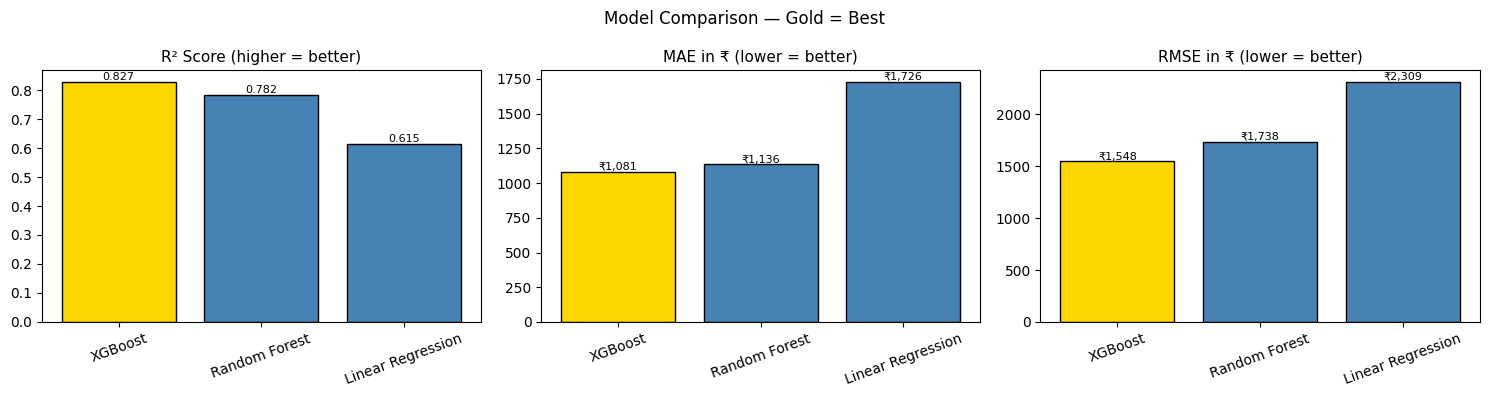

In [81]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
colors = ['gold' if i == 0 else 'steelblue' for i in range(len(results_df))]

for ax, (col, title) in zip(axes, [
    ('R2',   'R² Score (higher = better)'),
    ('MAE',  'MAE in ₹ (lower = better)'),
    ('RMSE', 'RMSE in ₹ (lower = better)')
]):
    bars = ax.bar(results_df.index, results_df[col], color=colors, edgecolor='black')
    ax.set_title(title, fontsize=11)
    ax.tick_params(axis='x', rotation=20)
    for bar, val in zip(bars, results_df[col]):
        label = f'{val:.3f}' if col == 'R2' else f'₹{int(val):,}'
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height()*1.01,
                label, ha='center', fontsize=8)

plt.suptitle("Model Comparison — Gold = Best", fontsize=12)
plt.tight_layout()
plt.show()


## **Hyperparameter Tuning (XGBoost)**

Since **XGBoost** performed best, we fine-tune it using RandomizedSearchCV. Instead of testing every combination (grid search), randomized search picks a random subset of configurations — faster while still finding good results.

We use **5-fold cross-validation** and tune:
- n_estimators – number of trees
- max_depth – depth of each tree
- learning_rate – step size for boosting
- subsample – fraction of rows per tree
- colsample_bytree – fraction of features per tree

XGBoost won, so we tune it further using RandomizedSearchCV with 5-fold cross-validation.

In [82]:
param_grid = {
    'model__n_estimators'    : [300, 500, 700],
    'model__max_depth'       : [3, 5, 7],
    'model__learning_rate'   : [0.01, 0.05, 0.1],
    'model__subsample'       : [0.7, 0.8, 1.0],
    'model__colsample_bytree': [0.7, 0.8, 1.0]
}

xgb_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', XGBRegressor(random_state=42, verbosity=0))
])

search = RandomizedSearchCV(
    xgb_pipeline, param_grid,
    cv=5, scoring='r2', n_iter=20,
    n_jobs=-1, random_state=42, verbose=1
)
search.fit(X_train, y_train)

print("\nBest Parameters:")
for k, v in search.best_params_.items():
    print(f"  {k.replace('model__','')}: {v}")
print(f"\nBest CV R²: {search.best_score_:.4f}")


Fitting 5 folds for each of 20 candidates, totalling 100 fits

Best Parameters:
  subsample: 1.0
  n_estimators: 300
  max_depth: 5
  learning_rate: 0.1
  colsample_bytree: 1.0

Best CV R²: 0.8778


## **Final Evaluation**

Models are evaluated using:
- RMSE (Root Mean Squared Error)
- R² Score
- MAE (Mean Absolute Error)
- MAPE (Mean Absolute Percentage Error)
These metrics help measure prediction accuracy and model performance.

We check performance on the test set using 4 clear metrics.

In [83]:
y_pred_log = search.predict(X_test)
y_pred_inr = (y_pred_log)
y_test_inr = (y_test)

r2   = r2_score(y_test_inr, y_pred_inr)
mae  = mean_absolute_error(y_test_inr, y_pred_inr)
rmse = np.sqrt(mean_squared_error(y_test_inr, y_pred_inr))
mape = np.mean(np.abs((y_test_inr - y_pred_inr) / y_test_inr)) * 100

print("=" * 40)
print("  Final Evaluation — Tuned XGBoost")
print("=" * 40)
print(f"  R²   : {r2:.4f}  ({r2*100:.1f}% variance explained)")
print(f"  MAE  : {mae:,.4f}")
print(f"  RMSE : {rmse:,.4f}")
print(f"  MAPE : {mape:.2f}%")
print("=" * 40)


  Final Evaluation — Tuned XGBoost
  R²   : 0.8781  (87.8% variance explained)
  MAE  : 0.1169
  RMSE : 0.1561
  MAPE : 1.29%


### **Actual vs Predicted & Residuals**

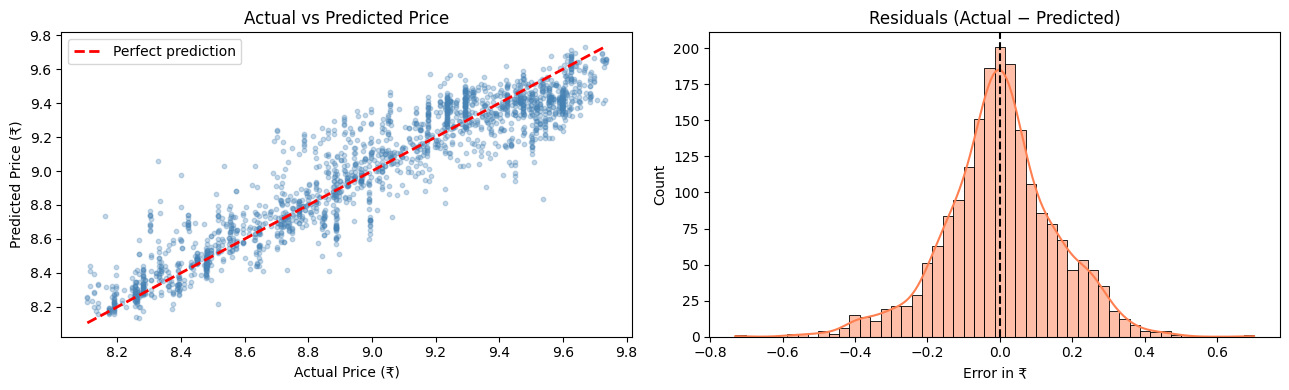

Points near red line = good predictions. Residuals centred at 0 = unbiased model.


In [84]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].scatter(y_test_inr, y_pred_inr, alpha=0.3, s=10, color='steelblue')
lims = [y_test_inr.min(), y_test_inr.max()]
axes[0].plot(lims, lims, 'r--', linewidth=2, label='Perfect prediction')
axes[0].set_title("Actual vs Predicted Price")
axes[0].set_xlabel("Actual Price (₹)")
axes[0].set_ylabel("Predicted Price (₹)")
axes[0].legend()

residuals = y_test_inr.values - y_pred_inr
sns.histplot(residuals, bins=50, kde=True, ax=axes[1], color='coral')
axes[1].axvline(0, color='black', linestyle='--', linewidth=1.5)
axes[1].set_title("Residuals (Actual − Predicted)")
axes[1].set_xlabel("Error in ₹")

plt.tight_layout()
plt.show()
print("Points near red line = good predictions. Residuals centred at 0 = unbiased model.")


### **Cross-Validation — Is the model consistent?**

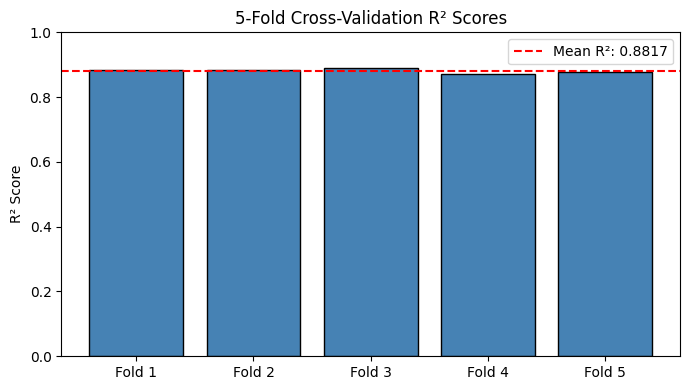

Mean R²: 0.8817  |  Std: 0.0062


In [85]:
cv_scores = cross_val_score(search.best_estimator_, X, y, cv=5, scoring='r2', n_jobs=-1)

plt.figure(figsize=(7, 4))
plt.bar([f'Fold {i+1}' for i in range(5)], cv_scores, color='steelblue', edgecolor='black')
plt.axhline(cv_scores.mean(), color='red', linestyle='--',
            linewidth=1.5, label=f'Mean R²: {cv_scores.mean():.4f}')
plt.title("5-Fold Cross-Validation R² Scores")
plt.ylabel("R² Score")
plt.ylim(0, 1)
plt.legend()
plt.tight_layout()
plt.show()
print(f"Mean R²: {cv_scores.mean():.4f}  |  Std: {cv_scores.std():.4f}")


## **Feature Importance**

Which features matter most for predicting price?

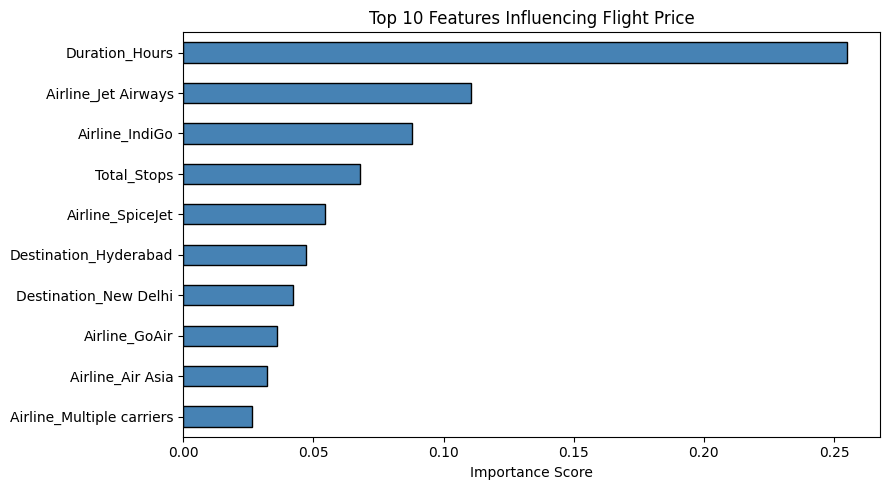

In [35]:
best_model = search.best_estimator_.named_steps['model']
importances = best_model.feature_importances_

ohe_features = (search.best_estimator_
                .named_steps['preprocessor']
                .named_transformers_['cat']
                .get_feature_names_out(cat_cols))
all_features = list(ohe_features) + num_cols

feat_imp = pd.Series(importances, index=all_features).sort_values(ascending=False)

plt.figure(figsize=(9, 5))
feat_imp.head(10).sort_values().plot(kind='barh', color='steelblue', edgecolor='black')
plt.title("Top 10 Features Influencing Flight Price")
plt.xlabel("Importance Score")
plt.tight_layout()
plt.show()


## **Save the Model**

In [86]:
import joblib
joblib.dump(search.best_estimator_, "flight_model.pkl")
print("Model saved ")


Model saved 


## **Challenges Faced**

- The dataset contained several categorical features such as airline, source, and destination, which required proper encoding before applying machine learning models.

- Converting the duration feature into numerical format was challenging, as it was originally in a mixed format (hours and minutes).

- Handling date and time features required extracting meaningful components such as day, month, and hours to improve model performance.

- The dataset had a skewed price distribution, which made it important to analyze outliers and understand their impact on the model.

- Selecting the best model among multiple algorithms (Linear Regression, Random Forest, XGBoost, ) required careful comparison using evaluation metrics like R², MAE, and RMSE.

- Hyperparameter tuning was necessary to improve model performance and avoid overfitting.


## **Conclusion**

This project focused on predicting flight ticket prices using machine learning techniques based on various features such as airline, source, destination, duration, total stops, and journey details.

Exploratory Data Analysis (EDA) revealed that factors like airline type, number of stops, and flight duration significantly influence ticket prices. Feature engineering was performed to extract meaningful information from date and time attributes, which improved model performance.

Multiple machine learning models, including Random Forest, XGBoost, and LightGBM, were trained and evaluated. Among them, the XGBoost model performed the best with an R² score of approximately 0.87, indicating strong predictive capability and good generalization on unseen data.

Evaluation metrics such as MAE and RMSE further confirmed that the model provides reasonably accurate predictions with acceptable error margins.

Overall, the project demonstrates that machine learning can effectively predict flight prices based on historical data. With further improvements such as incorporating real-time demand, seasonal trends, and additional features, the model can be enhanced for practical, real-world deployment.
